<a name='link2'>**<center><font size=6>Amazon Sales Dataset</font></center>**</a>

## Import necessary libraries..

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## Loading the dataset..

In [ ]:
# 1. mounted the drive into colab notebook
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 2. Load the dataset into pandas dataframe
df = pd.read_excel("/content/drive/MyDrive/Colab Notebooks/Tableau/Amazon_sales_dataset.xlsx")

## Data Overview..

In [ ]:
# 1. View the first 5 rows of the datset
df.head()

,Retailer,Retailer ID,Invoice Date,Region,State,City,Product,Price per Unit,Units Sold,Total Sales,Operating Profit,Operating Margin,Sales Method
0,Foot Locker,1185732,2020-01-01,Northeast,New York,New York,Men's Street Footwear,50.0,1200,600000.0,300000.0,0.50,In-store
1,Foot Locker,1185732,2020-01-02,Northeast,New York,New York,Men's Athletic Footwear,50.0,1000,500000.0,150000.0,0.30,In-store
2,Foot Locker,1185732,2020-01-03,Northeast,New York,New York,Women's Street Footwear,40.0,1000,400000.0,140000.0,0.35,In-store
3,Foot Locker,1185732,2020-01-04,Northeast,New York,New York,Women's Athletic Footwear,45.0,850,382500.0,133875.0,0.35,In-store
4,Foot Locker,1185732,2020-01-05,Northeast,New York,New York,Men's Apparel,60.0,900,540000.0,162000.0,0.30,In-store


In [ ]:
# 2. View the last 5 rows of the dataset
df.tail()

,Retailer,Retailer ID,Invoice Date,Region,State,City,Product,Price per Unit,Units Sold,Total Sales,Operating Profit,Operating Margin,Sales Method
9643,Foot Locker,1185732,2021-01-24,Northeast,New Hampshire,Manchester,Men's Apparel,50.0,64,3200.0,896.00,0.28,Outlet
9644,Foot Locker,1185732,2021-01-24,Northeast,New Hampshire,Manchester,Women's Apparel,41.0,105,4305.0,1377.60,0.32,Outlet
9645,Foot Locker,1185732,2021-02-22,Northeast,New Hampshire,Manchester,Men's Street Footwear,41.0,184,7544.0,2791.28,0.37,Outlet
9646,Foot Locker,1185732,2021-02-22,Northeast,New Hampshire,Manchester,Men's Athletic Footwear,42.0,70,2940.0,1234.80,0.42,Outlet
9647,Foot Locker,1185732,2021-02-22,Northeast,New Hampshire,Manchester,Women's Street Footwear,29.0,83,2407.0,649.89,0.27,Outlet


- The dataset contains information about different applicants.

In [ ]:
# 3. Understand the shape of the dataset
df.shape

(9648, 13)

- The dataset has 9,648 rows and 13 columns.

In [ ]:
# 4. Check the data types of the columns for the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9648 entries, 0 to 9647
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Retailer          9648 non-null   object        
 1   Retailer ID       9648 non-null   int64         
 2   Invoice Date      9648 non-null   datetime64[ns]
 3   Region            9648 non-null   object        
 4   State             9648 non-null   object        
 5   City              9648 non-null   object        
 6   Product           9648 non-null   object        
 7   Price per Unit    9648 non-null   float64       
 8   Units Sold        9648 non-null   int64         
 9   Total Sales       9648 non-null   float64       
 10  Operating Profit  9648 non-null   float64       
 11  Operating Margin  9648 non-null   float64       
 12  Sales Method      9648 non-null   object        
dtypes: datetime64[ns](1), float64(4), int64(2), object(6)
memory usage: 980.0+ KB


- There are 13 columns and 9,648 rows in the dataset.
- We have only six continuous variables - Retailer ID, Price per Unit, Units Sold, Total Sales, Operating Profit and Operating Margin.
- All other variables are categorical.
- The dataset contain no missing values.


In [ ]:
# 5. Checking for duplicate values
df.duplicated().sum()

np.int64(0)

- There are no duplicate values in the dataset.

In [ ]:
# 6. Checking for missing values
df.isnull().sum()

,0
Retailer,0
Retailer ID,0
Invoice Date,0
Region,0
State,0
City,0
Product,0
Price per Unit,0
Units Sold,0
Total Sales,0


- There are no missing values in this dataset.

In [ ]:
# 7. Statistical Summary
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Retailer ID,9648.0,1173849.72357,1128299.0,1185732.0,1185732.0,1185732.0,1197831.0,26360.377309
Invoice Date,9648,2021-05-10 15:20:44.776119296,2020-01-01 00:00:00,2021-02-17 00:00:00,2021-06-04 00:00:00,2021-09-16 00:00:00,2021-12-31 00:00:00,NaN
Price per Unit,9648.0,45.216625,7.0,35.0,45.0,55.0,110.0,14.705397
Units Sold,9648.0,256.930037,0.0,106.0,176.0,350.0,1275.0,214.25203
Total Sales,9648.0,93273.4375,0.0,4254.5,9576.0,150000.0,825000.0,141916.016727
Operating Profit,9648.0,34425.244761,0.0,1921.7525,4371.42,52062.5,390000.0,54193.113713
Operating Margin,9648.0,0.422991,0.1,0.35,0.41,0.49,0.8,0.097197


- **Date Range:** The dataset contains 9,648 transactions covering exactly two years, from January 1, 2020, to December 31, 2021.

- **Pricing & Margin:** The average price per unit is about 45. The business runs on a healthy average operating margin of 42%.

- **Huge Sales Outliers:** 50% of the transactions (median) generate 9,576 or less in total sales, but the highest single sale is a massive 825,000. This indicates a few extremely large bulk orders.

- **Profit Skew:** Similar to sales, the median operating profit is around 4,371, but the maximum profit from a single transaction reaches 390,000.

- **Units Sold:** The average order size is 257 units, but the largest order goes up to 1,275 units.

In [ ]:
# 8. Observation of categorical variables
# making list of all categorical variable
cat_col = [
    'Retailer',
    'Retailer ID',
    'Region',
    'State',
    'City',
    'Product',
    'Sales Method'
]

# Printing number of count of each unique value in each column
for col in cat_col:
  print(df[col].value_counts())
  print("-"*40)

Retailer
Foot Locker      2637
West Gear        2374
Sports Direct    2032
Kohl's           1030
Amazon            949
Walmart           626
Name: count, dtype: int64
----------------------------------------
Retailer ID
1185732    5265
1128299    2370
1197831    1653
1189833     360
Name: count, dtype: int64
----------------------------------------
Region
West         2448
Northeast    2376
Midwest      1872
South        1728
Southeast    1224
Name: count, dtype: int64
----------------------------------------
State
Texas             432
California        432
New York          360
Florida           360
Nevada            216
Pennsylvania      216
Alabama           216
Tennessee         216
Arkansas          216
Mississippi       216
New Mexico        216
Georgia           216
Arizona           216
Idaho             216
Oregon            216
Louisiana         216
Utah              216
Virginia          216
New Hampshire     216
Vermont           216
Connecticut       216
Rhode Island     

- **Top Retailers:** Foot Locker is the most active retailer with 2,637 transactions, followed closely by West Gear. Walmart handles the fewest transactions (626).
- **Categorical Behavior:** Even though Retailer ID contains numbers, the isolated, distinct blocks in the histogram show that it acts like a categorical label rather than a true continuous measurement.

- **Top Locations:** The West and Northeast are the busiest regions. Texas and California are the leading states (432 transactions each), and Portland is the top city.

- **Perfectly Balanced Products:** The transaction counts across all six product categories are remarkably even. Every category of men's and women's footwear and apparel has almost exactly the same number of transactions (between 1,606 and 1,610).

- **Dominant Sales Method:** "Online" is the most popular sales method by a wide margin (4,889 transactions), making up roughly half of the entire dataset. "In-store" sales are the least common.

## <a name='link2'>Exploratory Data Analysis (EDA)</a>

### Univariate Analysis

In [ ]:
def histogram_boxplot(data, feature, figsize=(12, 7), kde=True, bins=None):
    """
    Boxplot and histogram combined (Attractive Version)
    """
    # 1. Set a clean and professional background theme
    sns.set_theme(style="whitegrid", palette="pastel")

    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.2, 0.8)}, # Boxplot ko thoda patla aur hist ko bada kiya
        figsize=figsize,
    )

    # 2. Attractive Boxplot with Custom Colors & Outliers
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True,
        color="#FF9F36", # Vibrant Orange for the box
        flierprops={"marker": "o", "markerfacecolor": "#E74C3C", "markersize": 6, "alpha": 0.6}, # Highlight outliers in red
        meanprops={"marker": "^", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 8} # Pop-out mean triangle
    )
    ax_box2.set(xlabel="") # Remove overlapping x-label
    ax_box2.set_title(f"Distribution Analysis of {feature}", fontsize=16, fontweight='bold', color='#2C3E50', pad=15)

    # 3. Stylish Histogram with Edge Colors
    hist_kwargs = {
        "data": data,
        "x": feature,
        "kde": kde,
        "ax": ax_hist2,
        "color": "#3498DB", # Nice blue fill
        "edgecolor": "black", # Black borders for bins
        "linewidth": 1,
        "alpha": 0.7 # Slight transparency
    }

    if bins:
        sns.histplot(**hist_kwargs, bins=bins)
    else:
        sns.histplot(**hist_kwargs)

    # 4. Mean and Median Lines with Legends & Values
    mean_val = data[feature].mean()
    median_val = data[feature].median()

    ax_hist2.axvline(mean_val, color="#E74C3C", linestyle="--", linewidth=2.5, label=f"Mean: {mean_val:.2f}")
    ax_hist2.axvline(median_val, color="#2ECC71", linestyle="-", linewidth=2.5, label=f"Median: {median_val:.2f}")

    # 5. Formatting Labels, Legend, and Spines
    ax_hist2.legend(fontsize=11, frameon=True, shadow=True, loc="upper right")
    ax_hist2.set_xlabel(feature, fontsize=13, fontweight='bold', color='#34495E')
    ax_hist2.set_ylabel("Frequency", fontsize=13, fontweight='bold', color='#34495E')

    sns.despine(ax=ax_hist2) # Remove top and right borders
    sns.despine(ax=ax_box2, left=True) # Clean up boxplot borders

    plt.tight_layout()
    plt.show()

In [ ]:
def labeled_barplot(data, feature, perc=False, n=None, palette="viridis"):
    """
    Barplot with percentage or count at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    palette: color theme for the bars
    """
    # Total count calculation (ignoring missing values for accurate percentage)
    total = len(data[feature].dropna())
    count = data[feature].nunique()

    if n is None:
        plt.figure(figsize=(count + 3, 6))
    else:
        plt.figure(figsize=(n + 3, 6))

    # 1. Make the background style clean and modern
    sns.set_theme(style="whitegrid")

    # 2. Drawing a bar plot with vibrant colors and borders
    ax = sns.countplot(
        data=data,
        x=feature,
        palette=palette,
        order=data[feature].value_counts().index[:n],
        edgecolor="black",
        linewidth=1.5
    )

    # 3. formatting of Text aur Labels(Bold aur clear)
    plt.xticks(rotation=45, fontsize=12, fontweight='bold', ha='right')
    plt.yticks(fontsize=12)
    plt.title(f"Distribution of {feature.capitalize()}", fontsize=16, fontweight='bold', pad=15)
    plt.xlabel(feature.capitalize(), fontsize=14, fontweight='bold')
    plt.ylabel("Count", fontsize=14, fontweight='bold')

    for p in ax.patches:
        height = p.get_height()
        # If height is NaN then skip this
        if pd.isna(height) or height == 0:
            continue

        if perc == True:
            # BUG FIX: Your old code had '100p'; it needs to be changed to '100 * height'.
            label = "{:.1f}%".format(100 * height / total)
        else:
            label = int(height)

        x = p.get_x() + p.get_width() / 2
        y = height

        # 4. Making the annotations bold and shifting them slightly upwards
        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            fontweight='bold',
            color="black",
            xytext=(0, 8),
            textcoords="offset points",
        )

    # 5. Removing the top and right borders of the box for a clean look
    sns.despine(left=True, bottom=True)

    plt.tight_layout()
    plt.show()

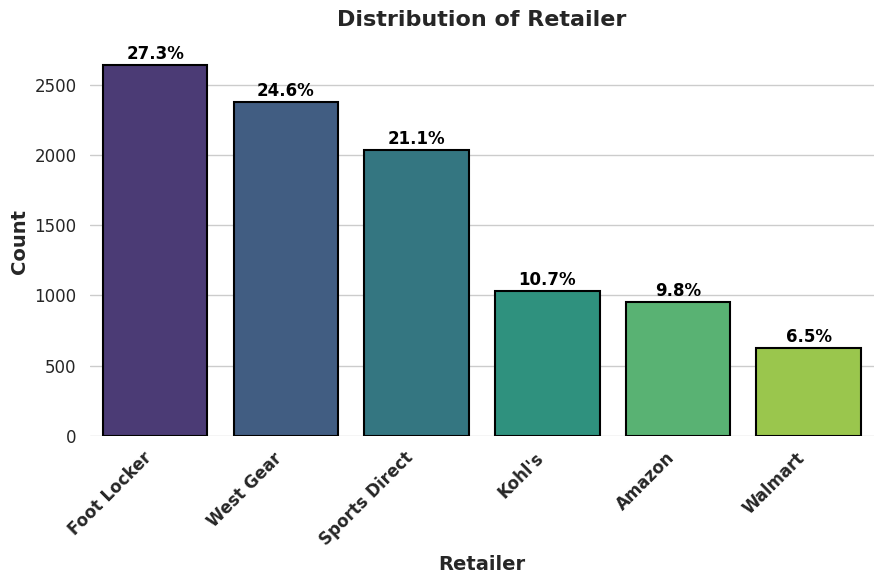

In [ ]:
# 1. Observation of "Retailer"
labeled_barplot(df, 'Retailer', perc=True)

- **Market Leader:** Foot Locker is the most active retailer in this dataset, handling 27.3% of all transactions.   
- **The Big Three:** The top three retailers (Foot Locker, West Gear, and Sports Direct) dominate the market, combining to make up exactly 73% of the total sales activity.   
- **Lowest Share:** Walmart handles the fewest transactions, representing just 6.5% of the dataset, closely followed by Amazon at 9.8%.

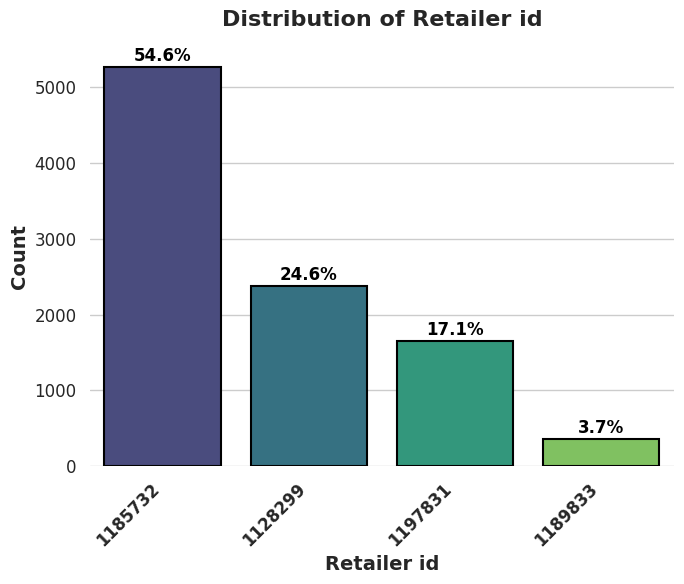

In [ ]:
# 2. Observation of "Retailer ID"
labeled_barplot(df, 'Retailer ID', perc=True)

- **Clear Majority:** A single retailer ID (1185732) dominates the dataset, accounting for more than half (54.6%) of all records.   
- **Top Heavy:** The top two retailer IDs (1185732 and 1128299) combined make up nearly 80% of the entire dataset.   
- **Smallest Contributor:** The retailer ID 1189833 is the least common, representing just 3.7% of the total transactions.   
- **Limited Unique IDs:** Despite the large volume of transactions, all records are linked to just four distinct retailer identification numbers.

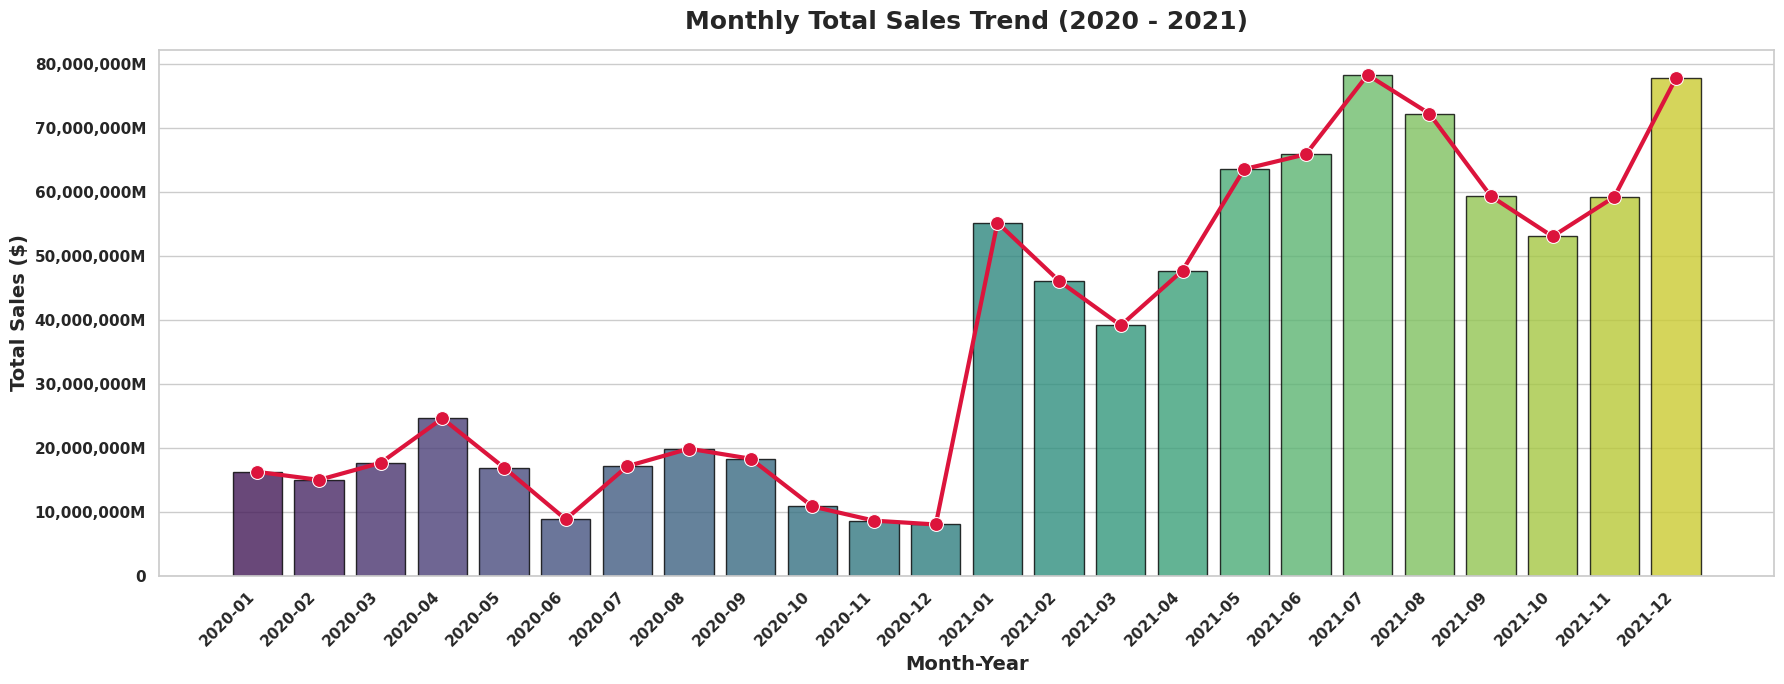

In [ ]:
# 3. Observation of 'Invoice Date'

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Extract 'Month-Year' from the date and group the data
df['Month_Year'] = df['Invoice Date'].dt.to_period('M').astype(str)
monthly_sales = df.groupby('Month_Year')['Total Sales'].sum().reset_index()

# 2. Set the figure size and overall styling
plt.figure(figsize=(18, 7))
sns.set_theme(style="whitegrid") # Clean background

# 3. Colorful Barplot (To show sales volume)
ax = sns.barplot(
    data=monthly_sales,
    x='Month_Year',
    y='Total Sales',
    palette='viridis',       # Attractive color gradient
    edgecolor='black',       # Sharp borders
    alpha=0.8                # Slight transparency for the bars
)

# 4. Highlighted Trend Line (To show the flow/trend over time)
sns.lineplot(
    data=monthly_sales,
    x='Month_Year',
    y='Total Sales',
    color='crimson',         # Contrasting color (Red) for the line
    marker='o',              # Dots on data points
    linewidth=3,             # Thick line
    markersize=10,           # Large dots
    ax=ax
)

# 5. Titles, Labels, and Aesthetics
plt.title("Monthly Total Sales Trend (2020 - 2021)", fontsize=18, fontweight='bold', pad=15)
plt.xlabel("Month-Year", fontsize=14, fontweight='bold')
plt.ylabel("Total Sales ($)", fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontweight='bold', fontsize=11)
plt.yticks(fontweight='bold', fontsize=11)

# 6. Format Y-axis numbers to be more readable (Millions/Thousands)
ylabels = ['{:,.0f}'.format(y) + 'M' if y >= 1e6 else '{:,.0f}'.format(y) for y in ax.get_yticks()]
ax.set_yticklabels(ylabels)

plt.tight_layout()
plt.show()

- **Massive Growth in 2021:** There is a huge and sudden jump in total sales starting in January 2021.   
- **Quiet 2020:** Throughout the entire year of 2020, sales were relatively low and stable, mostly staying under 25 million.   
- **Highest Peaks:** Sales reached their absolute highest points in July 2021 and December 2021, nearly hitting the 80 million mark.   
- **Lowest Point:** The lowest sales occurred right at the end of 2020 (November and December), just before the massive business boom in 2021.

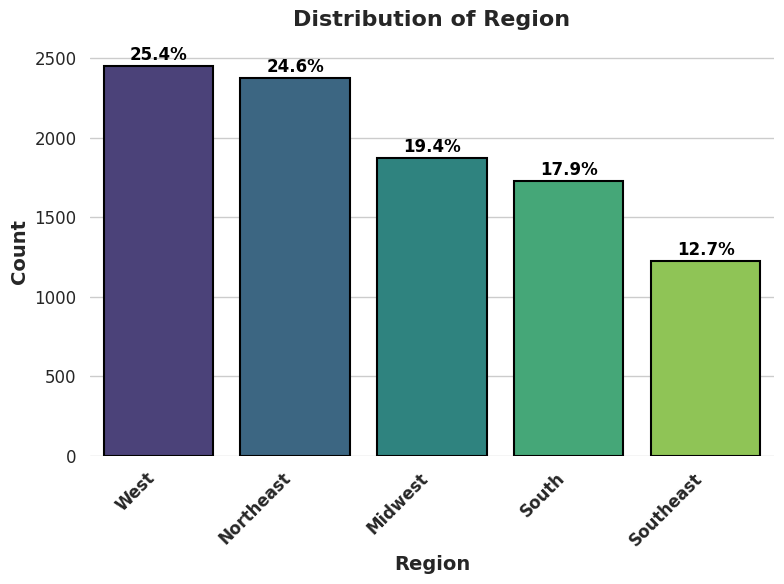

In [ ]:
# 4. Observation of 'Region'
labeled_barplot(df, 'Region', perc=True)

- **Top Performers:** The West and Northeast are the busiest regions, making up exactly half (50%) of all transactions combined.   
- **Market Leader:** The West region slightly edges out the rest to be the most active area, holding a 25.4% share of the dataset.   
- **Lowest Activity:** The Southeast is the least active region, representing only 12.7% of the total records.   
- **Clear Hierarchy:** There is a smooth, gradual step-down in transaction volume as you move from the top regions (West/Northeast) down to the Midwest, South, and finally the Southeast.  

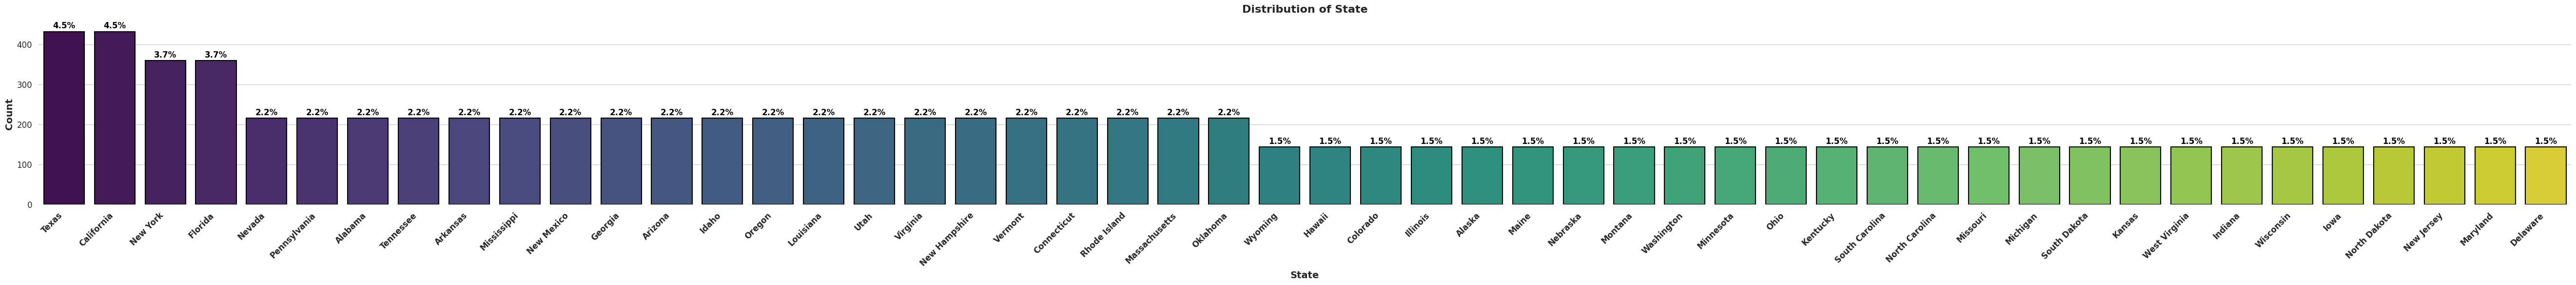

In [ ]:
# 5. Observation of 'State'
labeled_barplot(df, 'State', perc=True)

- **Top Markets:** Texas and California are the most active states, tying for the top spot with exactly 4.5% of the total transactions each.   
- **Secondary Leaders:** New York and Florida follow closely behind, each accounting for 3.7% of the dataset.   
- **Highly Uniform Tiers:** Instead of a random, natural spread, all the remaining states are perfectly grouped into just two flat tiers: a large middle group where every state sits at exactly 2.2%, and a final group where every state sits at exactly 1.5%.   
- **Key Takeaway:** The sales distribution across states is extremely rigid and structured. This stepped pattern suggests that transactions are tied to a fixed operational footprint (like a set number of stores or identical inventory allocations per state) rather than organic, random customer behavior.

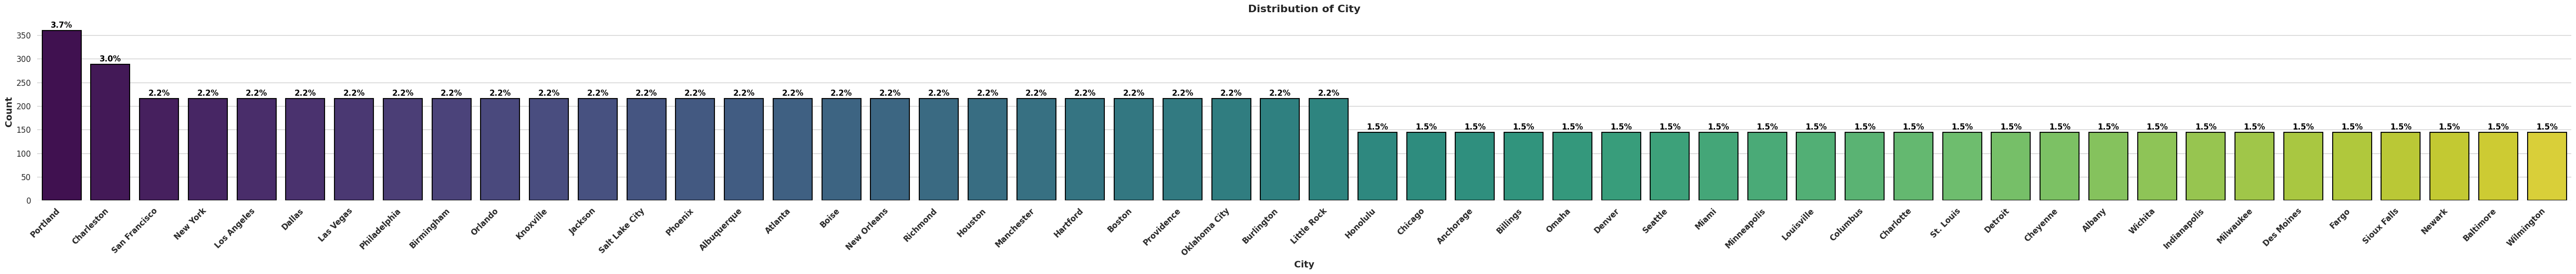

In [ ]:
# 6. Observation of 'City'
labeled_barplot(df, 'City', perc=True)

- **Top Locations:** Portland is the most active city in the dataset, making up 3.7% of the transactions, followed by Charleston at 3.0%.   
- **Rigid Tiers:** Just like the state distribution we saw earlier, the rest of the cities are not randomly distributed but are grouped into two perfectly flat levels.   
- **Middle Block:** A large group of cities (including San Francisco, New York, and Los Angeles) all sit at exactly 2.2% each.   
- **Bottom Block:** Every remaining city on the right side of the chart holds exactly 1.5% of the total records.   
- **Key Takeaway:** This perfectly stepped pattern strongly reinforces that the transactions are evenly distributed based on a fixed business structure (like having identical inventory allocations or a set number of days recorded for each city) rather than organic, random customer demand.

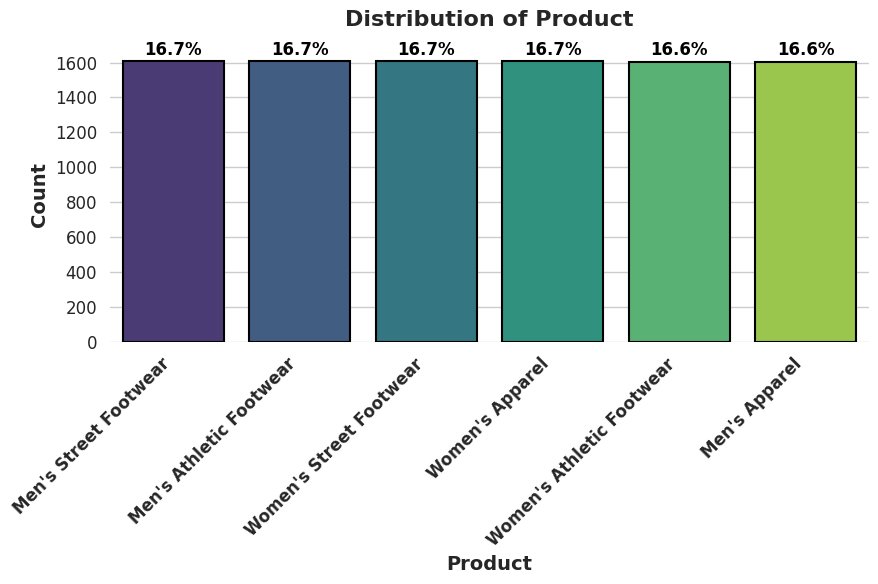

In [ ]:
# 7. Observation of 'Product'
labeled_barplot(df, 'Product', perc=True)

- **Perfectly Equal Split:** Every single product category has almost exactly the same number of transactions, making up either 16.6% or 16.7% of the dataset.   
- **No Best Sellers:** There is no dominant "best-selling" or "worst-selling" product here; all six categories (from Men's Street Footwear to Men's Apparel) are completely equally represented.   
- **Key Takeaway:** Just like the state and city distributions you saw earlier, this perfectly flat chart strongly confirms that the dataset is highly structured. It likely represents a fixed inventory allocation or a designed dataset rather than random, natural customer purchases.

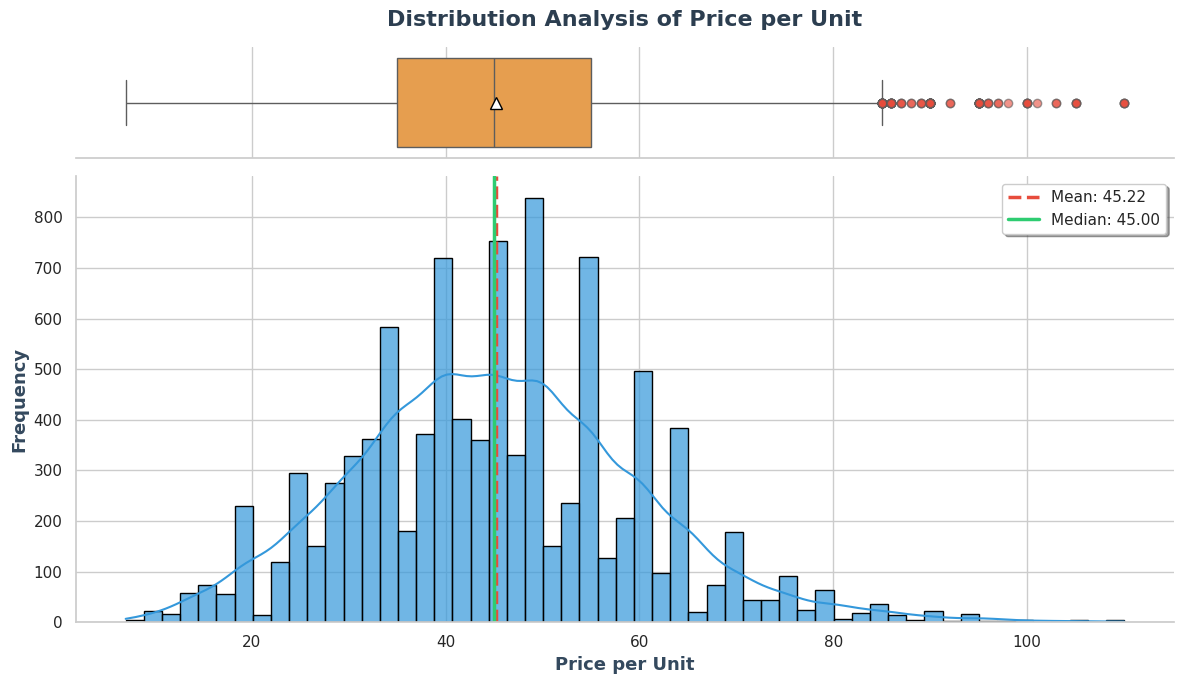

In [ ]:
# 8. Observation of 'Price Per Unit'
histogram_boxplot(df, 'Price per Unit')

- **Balanced Pricing:** The distribution has a very clean, bell-shaped curve, meaning most products are symmetrically priced around the average.   
- **Perfectly Centered:** The mean (45.22) and median (45.00) are almost identical, confirming that the prices are evenly distributed without a heavy pull to either side.   
- **Typical Price Range:** The vast majority of items fall within the 30 to 60 price range, which forms the tallest part of the histogram and the main orange box in the boxplot.   
- **Premium Outliers:** The red dots on the right side of the top boxplot show a few exceptionally high-priced outliers, stretching from around 85 up to 110.

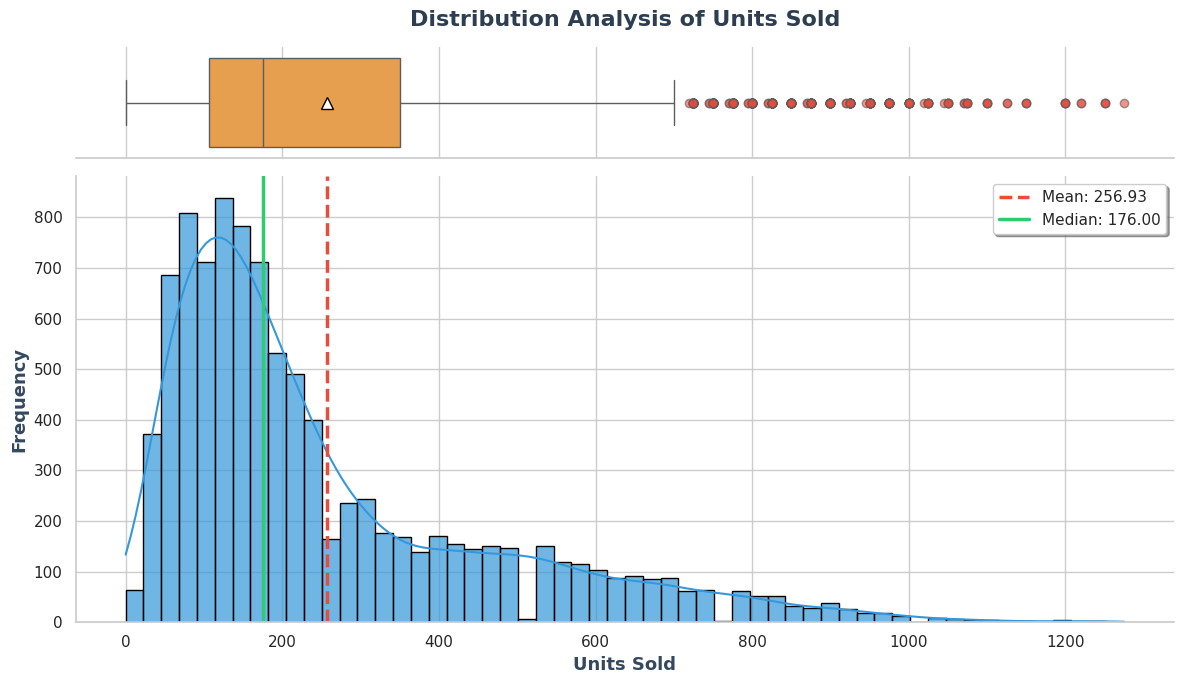

In [ ]:
# 9. Observation of 'Units Sold'
histogram_boxplot(df, 'Units Sold')

- **Most Orders are Small:** The vast majority of transactions involve a smaller number of items, with the bulk of the data heavily concentrated between roughly 50 and 250 units.   
- **Skewed Average:** Because the distribution is heavily skewed to the right, the mean (256.93) is pulled significantly higher than the median (176.00).   
- **Massive Bulk Orders:** The long tail on the right side of the histogram and the string of red dots in the top boxplot represent extreme outliers. This indicates that while most customers buy smaller quantities, there are rare but massive bulk orders reaching over 1,200 units in a single transaction.

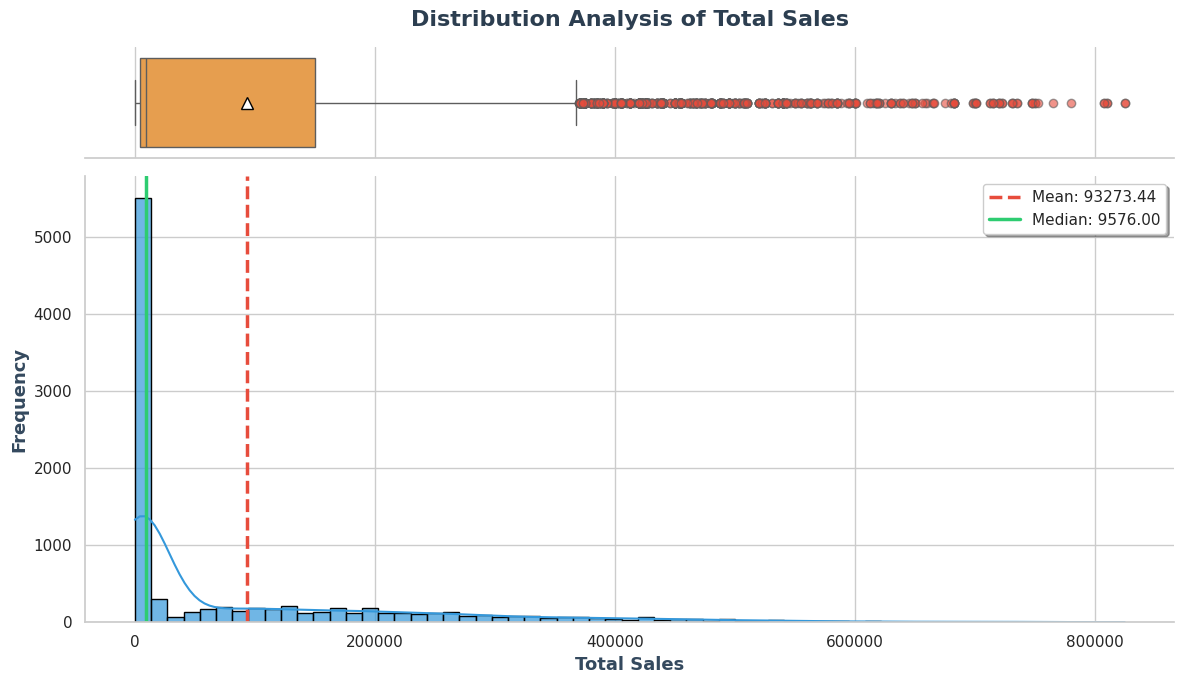

In [ ]:
# 10. Observation of 'Total Sales'
histogram_boxplot(df, 'Total Sales')

- **Most Sales are Small:** The vast majority of the transactions have a very low total sales value, which is heavily concentrated in a massive peak on the far left of the histogram.   
- **Huge Gap in Averages:** Due to the extreme right skew of the data, the mean (93,273.44) is dragged incredibly high, sitting almost ten times higher than the actual middle point or median (9,576.00).   
- **Extreme Outliers:** The very long trail of red dots in the top boxplot shows that while most typical orders are small, there are a few rare, massive transactions that exceed 800,000 in total sales.   
- **Key Takeaway:** Because the data is so heavily skewed by these massive outliers, your machine learning models (especially linear ones) might struggle. You should strongly consider applying a Log Transformation to this column before modeling.  

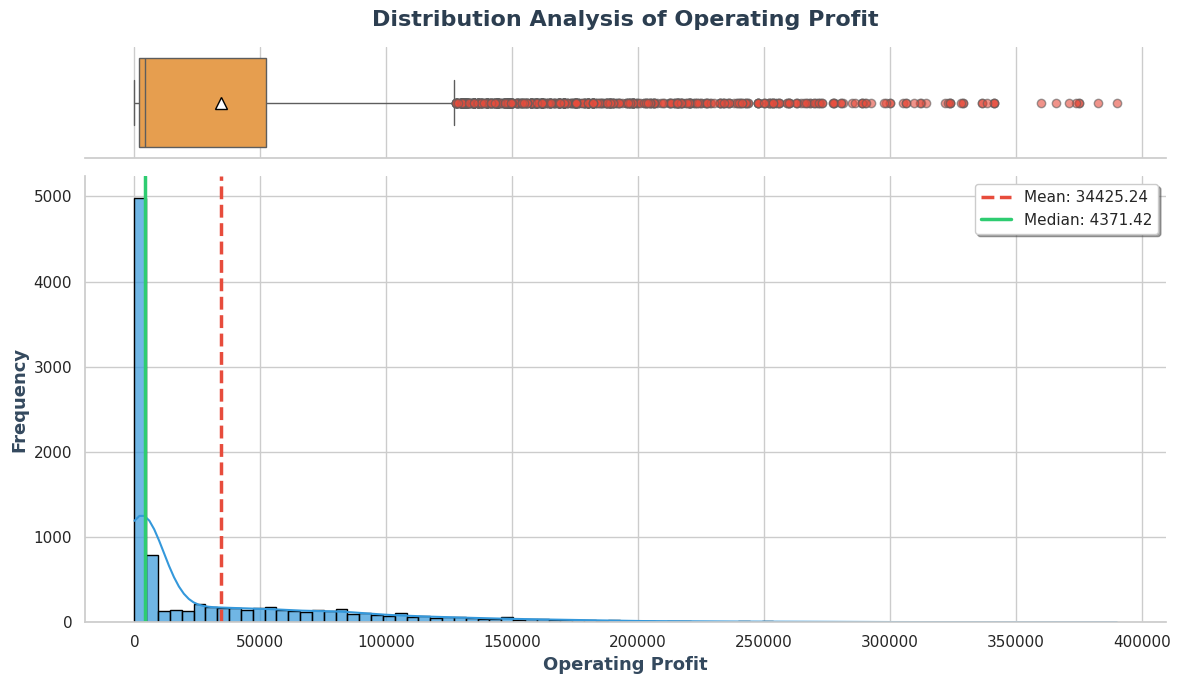

In [ ]:
# 11. Observation of 'Operating Profit'
histogram_boxplot(df, 'Operating Profit')

- **Mostly Small Profits:** Just like the total sales data, the vast majority of transactions generate a relatively small operating profit, causing a massive peak on the far left of the histogram.   
- **Heavily Skewed Average:** Because of the extreme right skew, the mean profit (34,425.24) is pulled drastically higher than the actual middle point or median (4,371.42).   
- **Massive Outliers:** The long, dense line of red dots in the top boxplot reveals rare but incredibly profitable transactions that reach nearly 400,000.   
- **Key Takeaway:** Since Operating Profit follows the exact same heavily distorted pattern as Total Sales, you should strongly consider applying a Log Transformation to this column as well before feeding it into your machine learning models

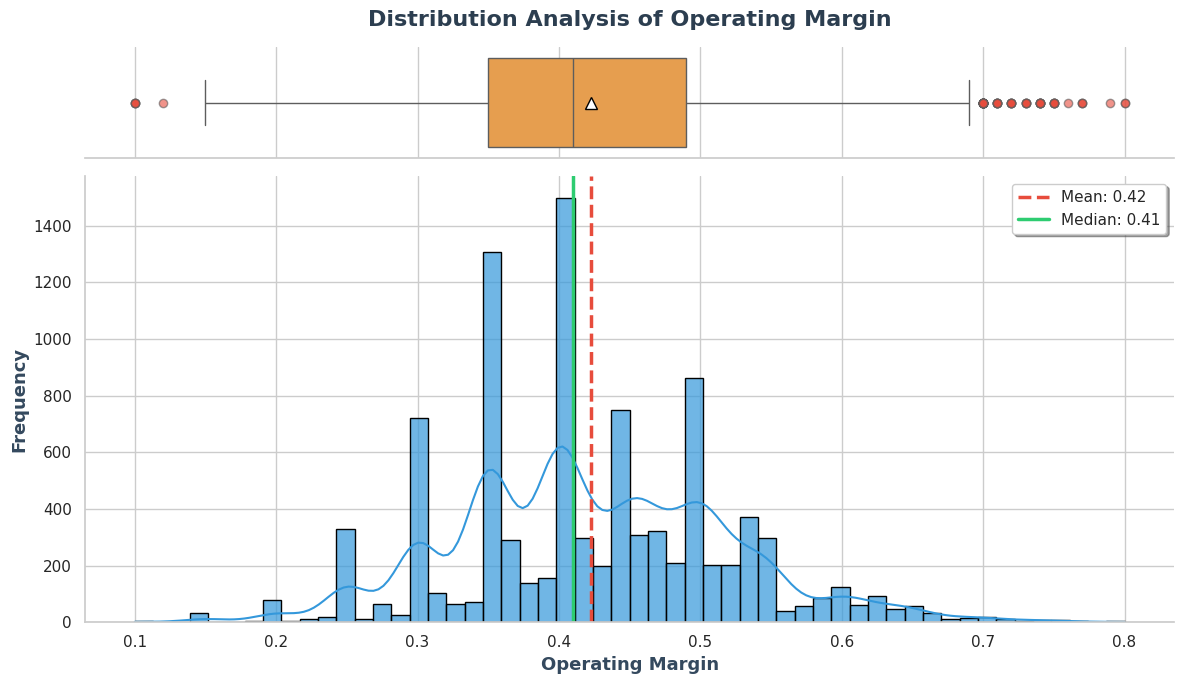

In [ ]:
# 12. Observation of 'Operating Margin'
histogram_boxplot(df, 'Operating Margin')

- **Well-Balanced Center:** The mean (0.42) and median (0.41) are nearly identical, showing that the overall operating margins are very well balanced around the 41-42% mark without extreme skewing.   
- **Fixed Margin Tiers:** Instead of a smooth curve, the histogram is very "spiky" with distinct, tall peaks at specific points like 0.30, 0.35, 0.40, and 0.50. This strongly suggests that the business applies fixed, standard percentage markups to its products rather than random pricing.   
- **Core Profitability:** The vast majority of the operating margins fall comfortably within the 35% to 55% range, representing the typical profitability zone for most transactions.   
- **Rare Extremes:** The red dots on the top boxplot show a few extreme cases, with margins occasionally dropping as low as 10% or soaring as high as 80%.

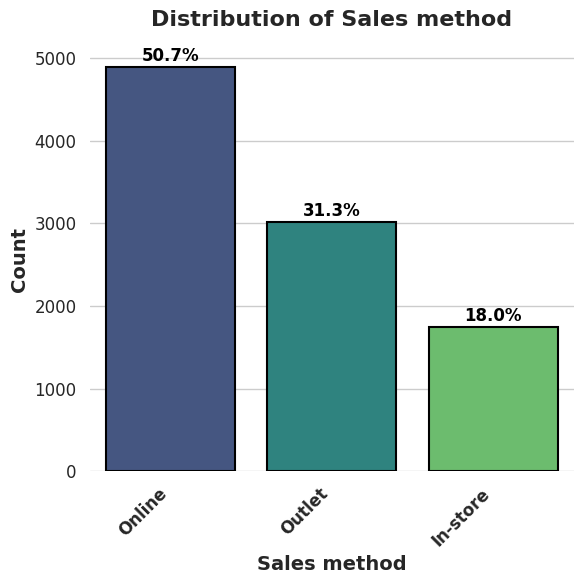

In [ ]:
# 13. Observation of 'Sales Method'
labeled_barplot(df, 'Sales Method', perc=True)

- **Well-Balanced Center:** The mean (0.42) and median (0.41) are nearly identical, showing that the overall operating margins are very well balanced around the 41-42% mark without extreme skewing.   
- **Fixed Margin Tiers:** Instead of a smooth curve, the histogram is very "spiky" with distinct, tall peaks at specific points like 0.30, 0.35, 0.40, and 0.50. This strongly suggests that the business applies fixed, standard percentage markups to its products rather than random pricing.   
- **Core Profitability:** The vast majority of the operating margins fall comfortably within the 35% to 55% range, representing the typical profitability zone for most transactions.   
- **Rare Extremes:** The red dots on the top boxplot show a few extreme cases, with margins occasionally dropping as low as 10% or soaring as high as 80%.

### Bivariate Analysis

In [ ]:
# 1. Categorical vs Numerical (Bar Plot)

def plot_cat_vs_num(df, cat_col, num_col):
    """
    Plots a bar chart to compare a numerical column across different categories.
    Example: Retailer vs Total Sales
    """
    plt.figure(figsize=(12, 6))
    sns.set_theme(style="whitegrid")

    # Create the bar plot summing up the numerical values
    ax = sns.barplot(
        data=df,
        x=cat_col,
        y=num_col,
        estimator=np.sum,
        errorbar=None,
        palette='viridis',
        edgecolor='black',
        linewidth=1.5
    )

    # Add titles and labels
    plt.title(f"Total {num_col} by {cat_col}", fontsize=16, fontweight='bold', pad=15)
    plt.xlabel(cat_col, fontsize=13, fontweight='bold')
    plt.ylabel(f"Total {num_col}", fontsize=13, fontweight='bold')
    plt.xticks(rotation=45, ha='right', fontweight='bold', fontsize=11)

    # Format Y-axis to show clean numbers
    ylabels = ['{:,.0f}'.format(y) for y in ax.get_yticks()]
    ax.set_yticklabels(ylabels)

    plt.tight_layout()
    plt.show()

# Use kaise karein:
# plot_cat_vs_num(df, cat_col='Retailer', num_col='Total Sales')

In [ ]:
# 2. Numerical vs Numerical (Scatter Plot)

def plot_num_vs_num(df, num_col1, num_col2, hue_col=None):
    """
    Plots a scatter plot to find the relationship between two numerical columns.
    Example: Total Sales vs Operating Profit
    """
    plt.figure(figsize=(12, 7))
    sns.set_theme(style="whitegrid")

    # Create the scatter plot
    sns.scatterplot(
        data=df,
        x=num_col1,
        y=num_col2,
        hue=hue_col,        # Add colors based on a third category (optional)
        palette='viridis',
        s=80,               # Size of dots
        alpha=0.7,          # Transparency
        edgecolor='black',
        linewidth=0.5
    )

    # Add titles and labels
    plt.title(f"Relationship between {num_col1} and {num_col2}", fontsize=16, fontweight='bold', pad=15)
    plt.xlabel(num_col1, fontsize=13, fontweight='bold')
    plt.ylabel(num_col2, fontsize=13, fontweight='bold')
    plt.xticks(fontweight='bold')
    plt.yticks(fontweight='bold')

    # Format the legend if hue is used
    if hue_col:
        plt.legend(title=hue_col, title_fontsize='12', fontsize='10', frameon=True, shadow=True)

    plt.tight_layout()
    plt.show()

# Use kaise karein:
# plot_num_vs_num(df, num_col1='Total Sales', num_col2='Operating Profit', hue_col='Sales Method')

In [ ]:
# 3. Categorical vs Categorical (Heatmap)


def plot_cat_vs_cat(df, cat_col1, cat_col2):
    """
    Plots a heatmap to show the count of combinations between two categorical columns.
    Example: Region vs Sales Method
    """
    plt.figure(figsize=(10, 6))

    # Create a cross-tabulation table
    cross_tab = pd.crosstab(df[cat_col1], df[cat_col2])

    # Create the heatmap
    sns.heatmap(
        cross_tab,
        annot=True,         # Show numbers inside boxes
        fmt='d',            # Integer format
        cmap='viridis',     # Colorful theme
        linewidths=1,
        linecolor='white'
    )

    # Add titles and labels
    plt.title(f"Distribution of {cat_col1} across {cat_col2}", fontsize=16, fontweight='bold', pad=15)
    plt.xlabel(cat_col2, fontsize=13, fontweight='bold')
    plt.ylabel(cat_col1, fontsize=13, fontweight='bold')
    plt.xticks(fontweight='bold', fontsize=11)
    plt.yticks(rotation=0, fontweight='bold', fontsize=11)

    plt.tight_layout()
    plt.show()

# How to Use:
# plot_cat_vs_cat(df, cat_col1='Region', cat_col2='Sales Method')

#### Categorical vs Numerical :-

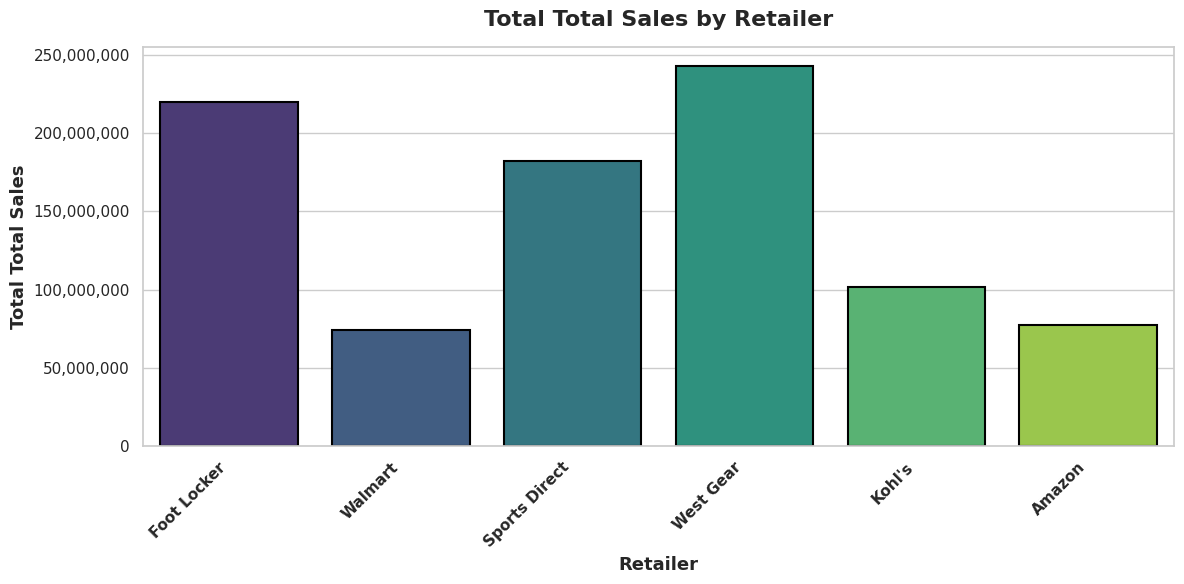

In [ ]:
# 1. Observatin of 'Retailer' vs 'Total Sales'
plot_cat_vs_num(df, cat_col='Retailer', num_col='Total Sales')

- **Top Performer:** West Gear generates the highest total sales, reaching nearly 250 million.   
- **Strong Runner-Up:** Foot Locker is the second most profitable retailer, bringing in over 200 million in sales.   
- **Lowest Revenue:** Walmart and Amazon have the lowest total sales among the group, both bringing in roughly 75 million.   
- **Middle Tier:** Sports Direct performs strongly in third place at around 180 million, while Kohl's sits lower, just barely passing the 100 million mark.

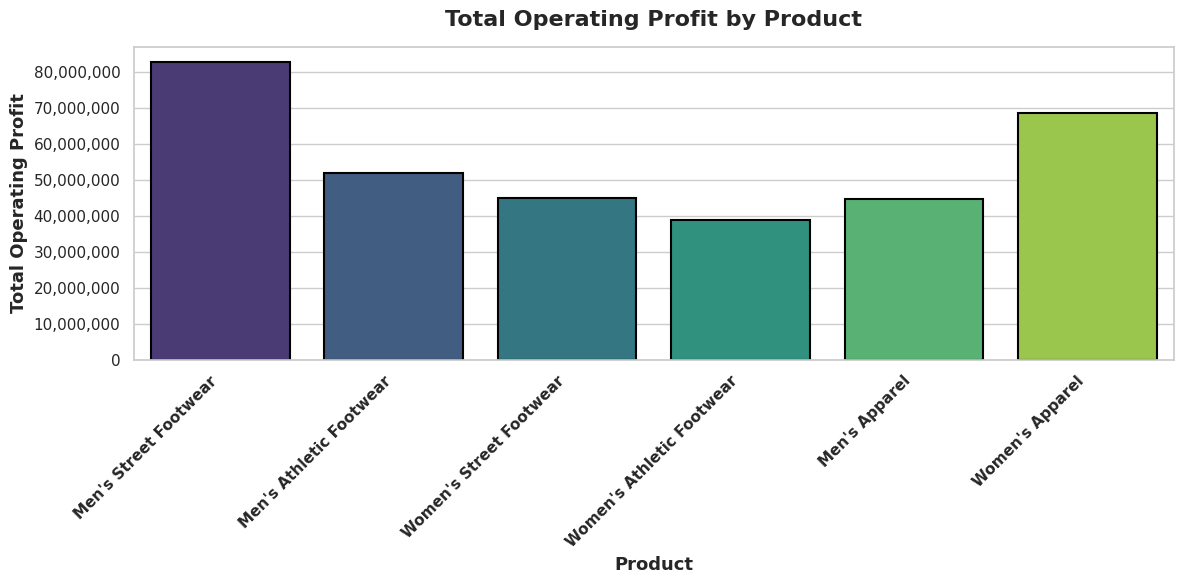

In [ ]:
# 2. Observation of 'Product' vs 'Operating Profit'
plot_cat_vs_num(df, cat_col='Product', num_col='Operating Profit')

- **Top Earner:** Men's Street Footwear is by far the most profitable product category, generating over 80 million in operating profit.   
- **Strong Second:** Women's Apparel follows as the second most profitable category, bringing in nearly 70 million.   
- **Lowest Profit:** Women's Athletic Footwear generates the least amount of profit, falling just below the 40 million mark.   
- **Middle Tier:** Men's Athletic Footwear, Women's Street Footwear, and Men's Apparel sit comfortably in the middle, each generating between 40 million and 55 million.   

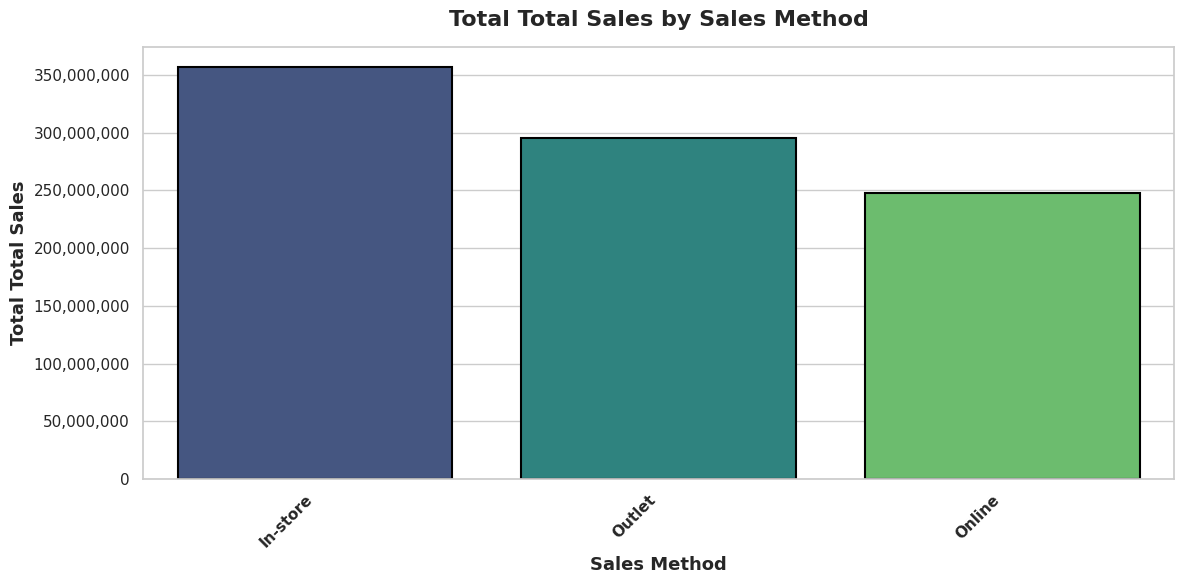

In [ ]:
# 3. Observation of 'Sales Method' vs 'Total Sales'
plot_cat_vs_num(df, cat_col='Sales Method', num_col='Total Sales')

- **Revenue Leader:** In-store transactions generate the highest total revenue, bringing in over 350 million.   
- **Volume vs. Value Contrast:** Even though previous charts showed "Online" had the highest number of transactions, it generates the lowest total sales revenue, hovering around 250 million. This means online customers make many small purchases, while in-store customers make fewer but much larger purchases.   
- **Steady Middle:** The Outlet channel sits comfortably in the middle, generating nearly 300 million in total sales.

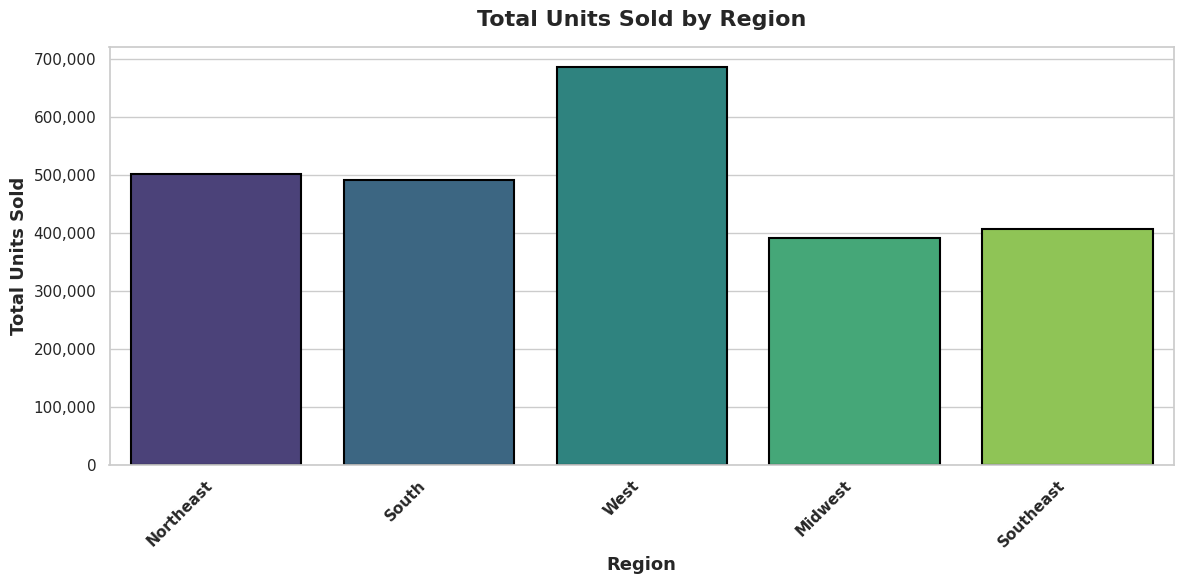

In [ ]:
# 4. Observation of 'Region' vs 'Units Sold'
plot_cat_vs_num(df, cat_col='Region', num_col='Units Sold')

- **Clear Winner:** The West region strongly leads in sales volume, moving nearly 700,000 total units.   
- **Consistent Middle:** The Northeast and South regions perform very similarly, both selling roughly 500,000 units.   
- **Lowest Volume:** The Midwest and Southeast regions have the lowest sales numbers, both hovering around the 400,000 mark.

#### Numerical vs Numerical :-

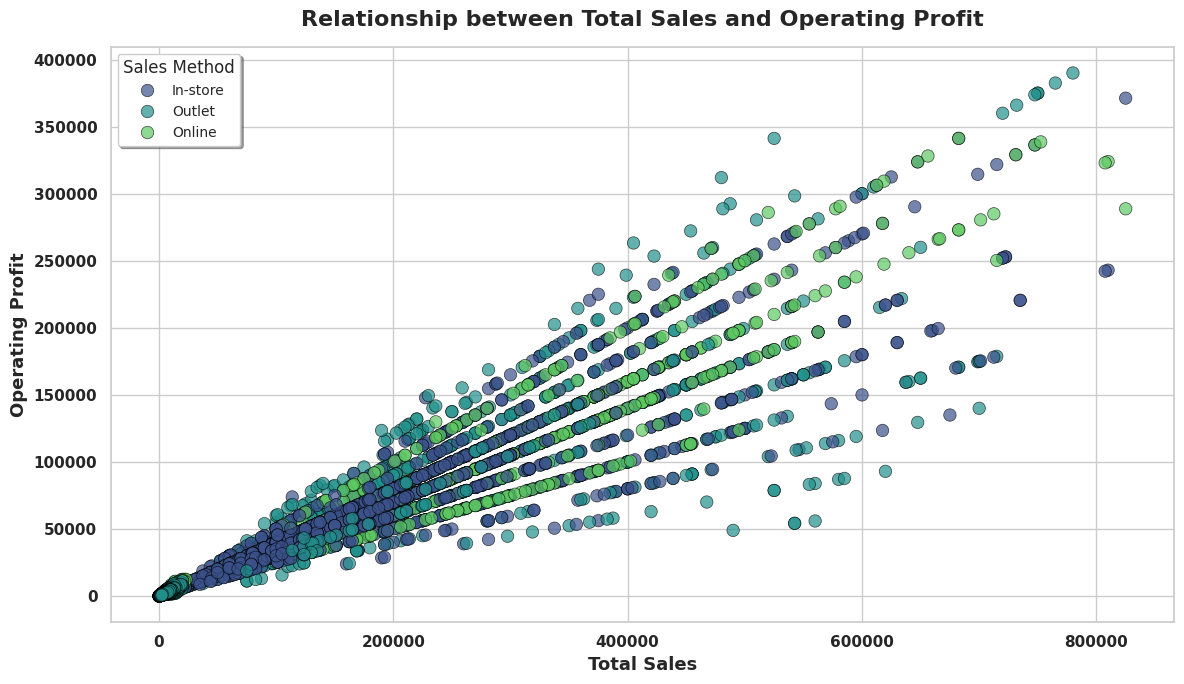

In [ ]:
# 1. Observation of 'Total Sales' vs 'Operating Profit'
plot_num_vs_num(df, num_col1='Total Sales', num_col2='Operating Profit', hue_col='Sales Method')

- **Direct Correlation:** There is a strong, positive relationship between total sales and operating profit; as sales increase, profit reliably increases as well.   
- **Fixed Profit Margins:** Instead of a random, messy cloud, the data points form distinct, straight lines radiating outward like a fan. This perfectly visualizes that the business applies strict, fixed percentage markups to its products.   
- **Heavy Concentration:** The massive, dense cluster of dots in the bottom-left corner confirms that the vast majority of individual transactions are small in both sales volume and profit.   
- **Mixed Channels:** The colors representing the three sales methods (Online, Outlet, and In-store) are spread out across all the different profit lines. This means no single sales method is locked into just one high or low profit margin.

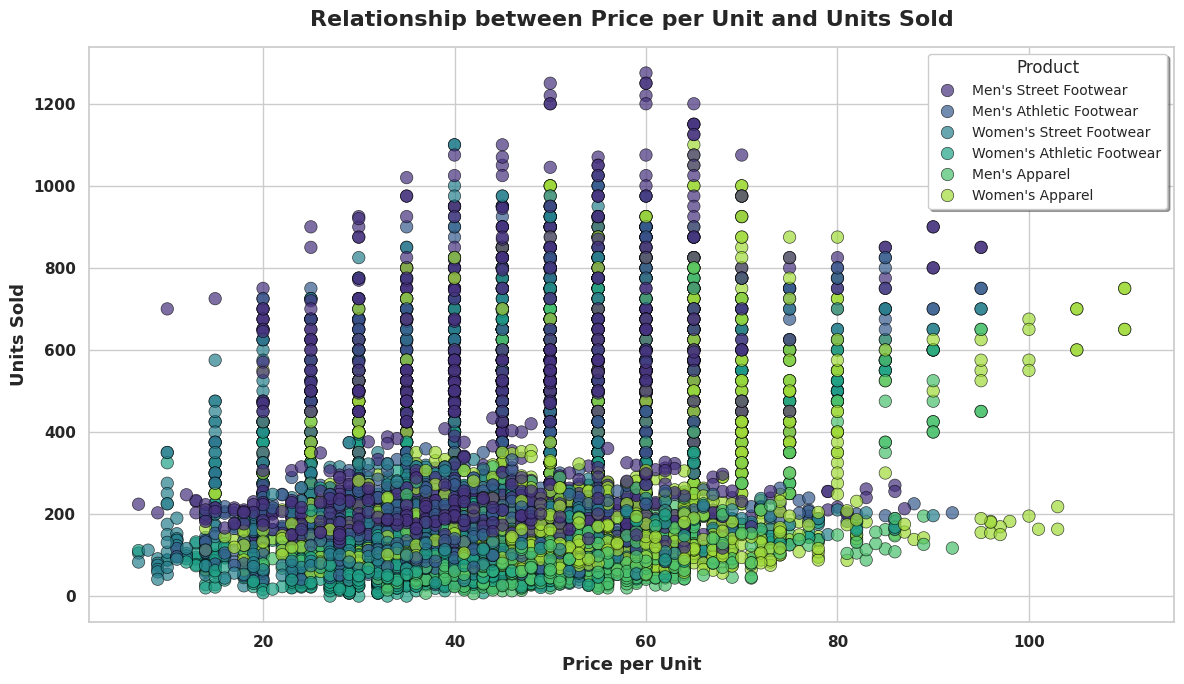

In [ ]:
# 2. Observation of 'Price per Units' vs 'Units Sold'
plot_num_vs_num(df, num_col1='Price per Unit', num_col2='Units Sold', hue_col='Product')

- **Fixed Price Points:** The data points form perfectly straight vertical lines, indicating that products are sold at specific, set price tiers (such as 40, 50, or 60) rather than at random, continuous prices.   
- **Small Orders Dominate:** Regardless of the price, the vast majority of transactions involve smaller quantities, forming a dense cluster at the bottom of the chart below 400 units sold.   
- **Bulk Buying Sweet Spot:** The rare, massive bulk orders (reaching 1,000 to 1,200 units) primarily occur in the mid-price range between 40 and 70, rather than with the cheapest items.   
- **Premium Drop-off:** As the price per unit rises above 80, the maximum number of units sold per transaction drops significantly, showing that expensive items are rarely purchased in large bulk quantities.   
- **Category Leader:** Men's Street Footwear (represented by the highest dark purple dots) is the most common product category involved in those extreme high-volume bulk purchases.

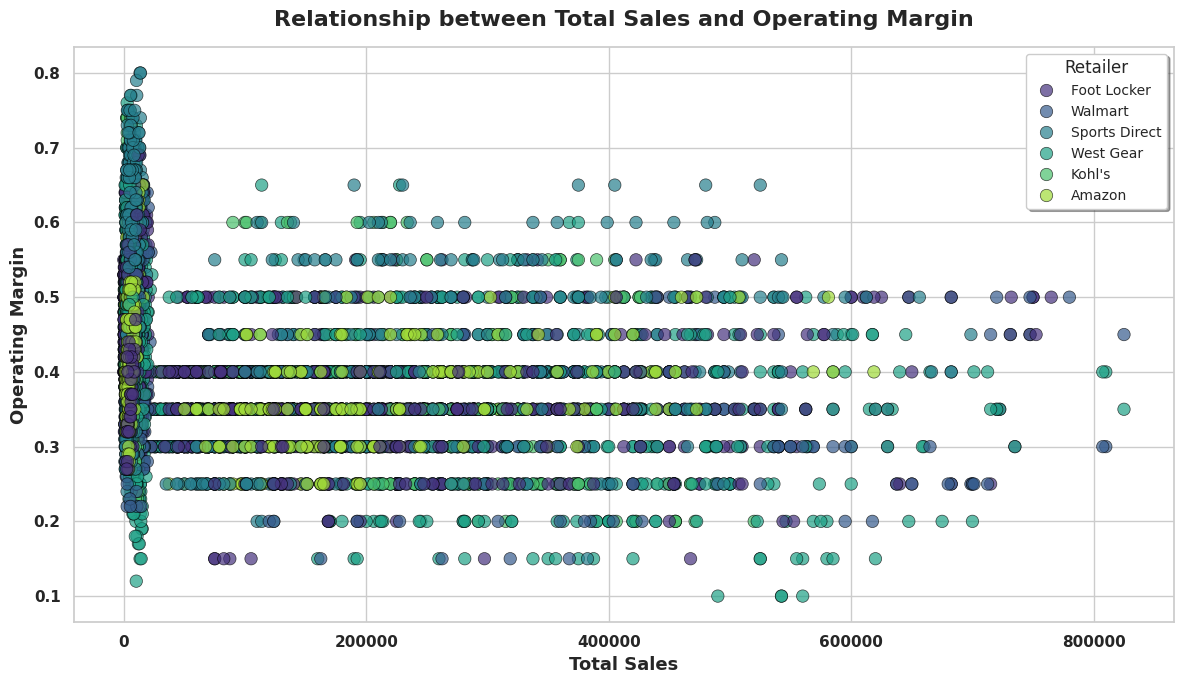

In [ ]:
# 3. Observation of 'Total Sales' vs 'Operating Margin'
plot_num_vs_num(df, num_col1='Total Sales', num_col2='Operating Margin', hue_col='Retailer')

- **Fixed Margin Tiers:** The data points form perfectly straight horizontal lines, proving that operating margins are set at strict, fixed percentages (like 30%, 35%, 40%, 45%, and 50%) rather than being random or dynamic.   
- **Massive Small-Sale Cluster:** There is a huge, dense vertical pillar on the far left of the chart. This shows that the vast majority of transactions have very low total sales, but these small sales can have any profit margin, ranging from 10% all the way up to 80%.   
- **Big Sales Mean Lower Margins:** As total sales increase (moving to the right), the highest profit margins disappear. The rare, massive transactions exceeding 600,000 in sales generally max out at around a 45% or 50% margin, showing that bulk or high-value orders get lower percentage markups.   
- **Shared Retailer Strategy:** The mixed colors across the horizontal lines show that all retailers (like Walmart, Foot Locker, and Amazon) follow these exact same fixed margin tiers. No single retailer has a monopoly on the highest or lowest margins.  

#### Categorical vs Categorical

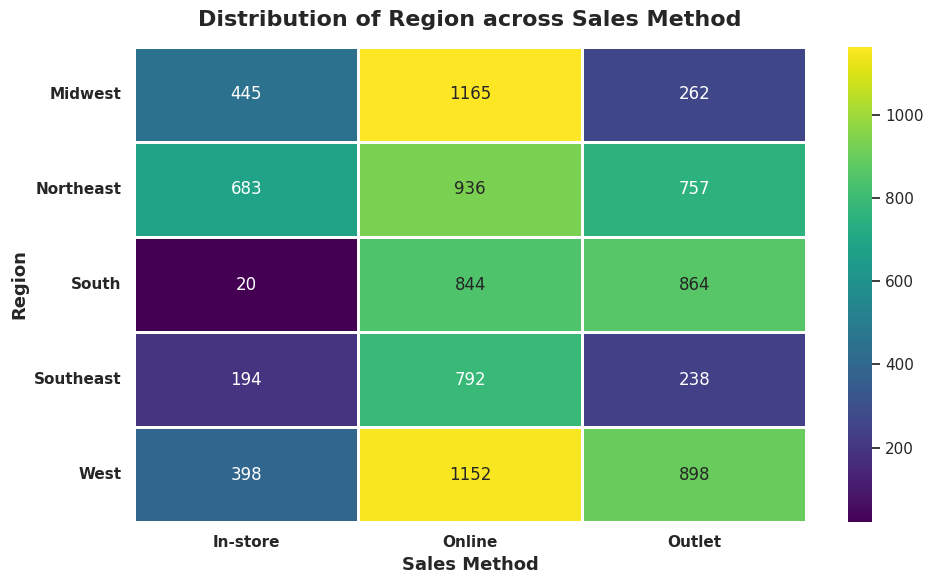

In [ ]:
# 1. Observation of 'Region' vs 'Sales Method'
plot_cat_vs_cat(df, cat_col1='Region', cat_col2='Sales Method')

- **Online is King:** "Online" is clearly the most preferred sales method across almost every region, highlighted by the bright yellow blocks representing the highest transaction counts in the Midwest (1,165) and the West (1,152).   
- **The "In-store" Dead Zone:** The South region has almost zero in-store foot traffic, recording an extreme low of just 20 transactions (the darkest purple box on the chart).   
- **The Most Balanced Region:** The Northeast is the only region where customers shop very evenly across all three channels, showing a healthy mix of In-store (683), Online (936), and Outlet (757) transactions.   
- **Mixed Outlet Popularity:** Outlet shopping is highly popular in the West (898) and South (864), but struggles significantly to attract customers in the Midwest (262) and Southeast (238).  

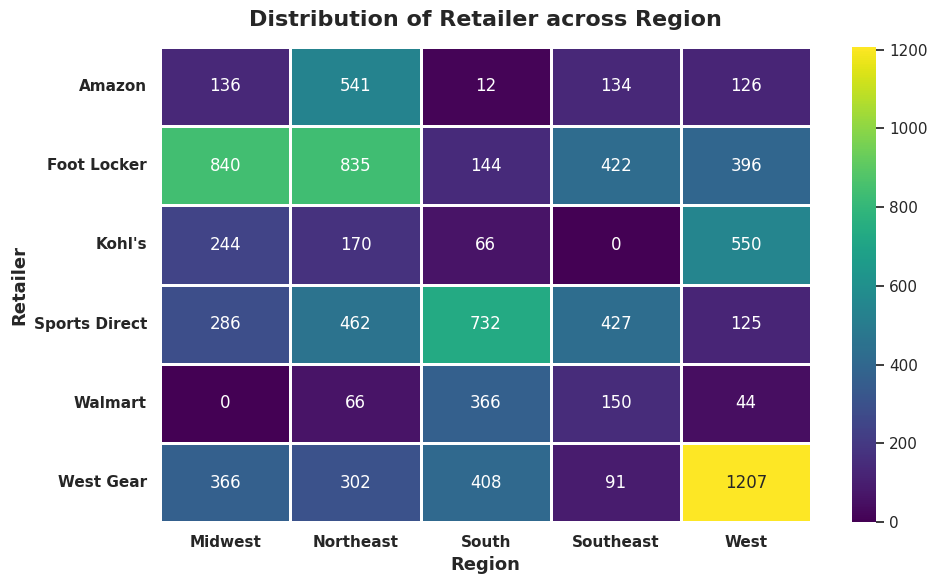

In [ ]:
# 2. Observation of 'Retailer' vs 'Region'
plot_cat_vs_cat(df, cat_col1='Retailer', cat_col2='Region')

- **Western Dominance:** West Gear completely dominates the West region, recording the absolute highest transaction count (1,207) on the entire board, shown by the bright yellow box.   
- **Dead Zones:** There are major gaps in regional coverage; Walmart has absolutely zero transactions in the Midwest, and Kohl's has exactly zero presence in the Southeast.   
- **Northern Stronghold:** Foot Locker is highly successful in the northern areas, holding the top spots in both the Midwest (840) and the Northeast (835).   
- **Southern Leader:** Sports Direct is the most popular retailer in the South with 732 transactions, easily beating out all other competitors in that specific region.  

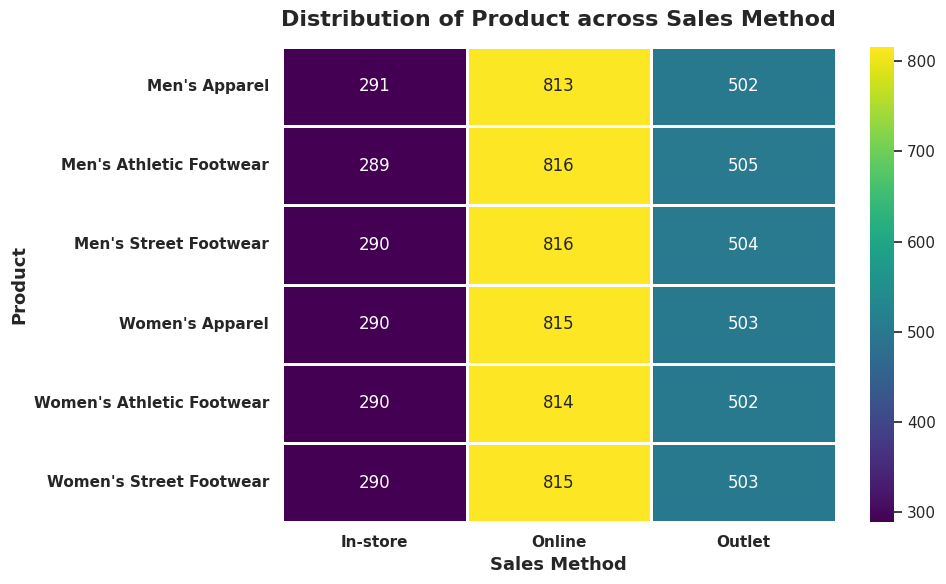

In [ ]:
# 3. Observation of 'Product' vs 'Sales Method'
plot_cat_vs_cat(df, cat_col1='Product', cat_col2='Sales Method')

- **Online Dominance:** "Online" is consistently the most popular sales channel for every single product category, with transaction counts heavily concentrated around 814 to 816 for each item.   
- **In-Store Lag:** Traditional "In-store" shopping is the least utilized method across the board, recording an almost identical baseline of about 290 transactions for every product type.   
- **Perfect Uniformity:** The most striking feature of this chart is its completely even and symmetrical distribution; no matter what the product is, the exact ratio of In-store, Online, and Outlet sales remains perfectly flat.   
- **Key Takeaway:** Just like the univariate charts showed perfectly equal product counts earlier, this heatmap strongly confirms that the dataset is highly structured or artificially allocated. Natural customer shopping behavior rarely results in all products having the exact same sales channel preferences down to the single digit.   